# 1. Agents and sanity checks
**Project:** Does evolution favour optimistic learners in social dilemmas?

Before evolving anything, I check that the learning agents behave sensibly:
1. Does a single agent learn which of two slot machines (a "2-armed bandit") is better?
2. When pairs of agents with fixed biases play the Iterated Prisoner's Dilemma (IPD), how much do they cooperate?

**Agent:** tabular Q-learning with separate learning rates for positive (α⁺) and negative (α⁻) prediction errors
(Lefebvre et al., 2017; Palminteri & Lebreton, 2022). In the IPD, the agent's state is its partner's last move.
Optimism bias: α⁺ > α⁻. Pessimism bias: α⁺ < α⁻.

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

## Model code
This cell contains the full contents of `ipd.py`, so the notebook runs on its own (e.g. in Google Colab) without uploading any other files.

In [2]:
"""
ipd.py -- Iterated Prisoner's Dilemma with asymmetric Q-learning agents
=======================================================================
Project: Does evolution favour optimistic learners in social dilemmas?
Extends Hoxha, Sperber & Palminteri (2025, PNAS) from individual bandit
tasks to social interaction.

Contents
--------
* PD payoffs (Axelrod's T=5, R=3, P=1, S=0), rescaled to [0, 1]
* QAgent: tabular Q-learning with SEPARATE learning rates for
  positive (alpha_pos) and negative (alpha_neg) prediction errors,
  softmax choice (inverse temperature beta), applied to (1 - gamma) * Q so
  choice noise does not depend on gamma; starting values 0.5 / (1 - gamma)
* play_match(): two agents play a repeated game and learn online
"""

import numpy as np

C, D = 0, 1                              # actions: cooperate, defect
ACTIONS = ("C", "D")

# Payoffs to the ROW player: PAYOFF[my_action, their_action]
T, R, P, S = 5, 3, 1, 0
PAYOFF = np.array([[R, S],
                   [T, P]], dtype=float) / T   # rescale to [0, 1]

# States = what the opponent did last round (0 = C, 1 = D);
# state 2 = first round (no history yet).
N_STATES, N_ACTIONS = 3, 2


class QAgent:
    """Tabular Q-learner with asymmetric learning rates.

    Update rule (Lefebvre et al., 2017; Palminteri & Lebreton, 2022):
        delta = r + gamma * max_a' Q(s', a') - Q(s, a)
        Q(s, a) += alpha_pos * delta   if delta > 0
                   alpha_neg * delta   otherwise
    Optimism bias  : alpha_pos > alpha_neg
    Pessimism bias : alpha_pos < alpha_neg
    """

    def __init__(self, alpha_pos=0.3, alpha_neg=0.3, beta=10.0,
                 gamma=0.9, q_init=None, rng=None):
        self.alpha_pos, self.alpha_neg = alpha_pos, alpha_neg
        self.beta, self.gamma = beta, gamma
        self.q_init = 0.5 / (1 - gamma) if q_init is None else q_init
        self.rng = rng if rng is not None else np.random.default_rng()
        self.reset()

    def reset(self):
        self.Q = np.full((N_STATES, N_ACTIONS), self.q_init)

    def choose(self, state):
        q = self.Q[state] * (1 - self.gamma)
        z = self.beta * (q - q.max())               # numerically stable softmax
        p = np.exp(z) / np.exp(z).sum()
        return self.rng.choice(N_ACTIONS, p=p)

    def update(self, state, action, reward, next_state):
        target = reward + self.gamma * self.Q[next_state].max()
        delta = target - self.Q[state, action]
        lr = self.alpha_pos if delta > 0 else self.alpha_neg
        self.Q[state, action] += lr * delta
        return delta

    @property
    def bias(self):
        """Normalised optimism index in [-1, 1] (Palminteri-style)."""
        return (self.alpha_pos - self.alpha_neg) / (self.alpha_pos + self.alpha_neg)


def play_match(a1, a2, n_rounds=200, noise=0.0, rng=None):
    """Two agents play n_rounds of the PD, learning online.

    noise: probability that an intended action is flipped (trembling hand),
           which makes the environment stochastic.
    Returns arrays (n_rounds,) of each agent's actions and payoffs.
    """
    rng = rng if rng is not None else np.random.default_rng()
    s1 = s2 = 2                                    # first-round state
    acts = np.zeros((n_rounds, 2), dtype=int)
    pays = np.zeros((n_rounds, 2))
    for t in range(n_rounds):
        x1, x2 = a1.choose(s1), a2.choose(s2)
        if noise > 0:
            if rng.random() < noise: x1 = 1 - x1
            if rng.random() < noise: x2 = 1 - x2
        r1, r2 = PAYOFF[x1, x2], PAYOFF[x2, x1]
        ns1, ns2 = x2, x1                          # next state = opponent's move
        a1.update(s1, x1, r1, ns1)
        a2.update(s2, x2, r2, ns2)
        s1, s2 = ns1, ns2
        acts[t] = (x1, x2)
        pays[t] = (r1, r2)
    return acts, pays


## Check 1: a single agent learns a 2-armed bandit (p = 0.3 vs 0.7)

In [3]:
rng = np.random.default_rng(2026)

def bandit_run(agent, n_trials=200, p=(0.3, 0.7)):
    correct = np.zeros(n_trials)
    for t in range(n_trials):
        a = agent.choose(2)                       # single state
        r = float(rng.random() < p[a])
        agent.update(2, a, r, 2)
        correct[t] = a == 1
    return correct

learn = np.mean([bandit_run(QAgent(rng=rng, beta=8, gamma=0.0)) for _ in range(300)], axis=0)
print(f"Bandit accuracy, last 50 trials: {learn[-50:].mean():.2f} (should be > 0.6)")

Bandit accuracy, last 50 trials: 0.94 (should be > 0.6)


## Check 2: cooperation between agent types in the IPD (noise = 0.05)

In [4]:
TYPES = {
    "unbiased":    dict(alpha_pos=0.30, alpha_neg=0.30),
    "optimistic":  dict(alpha_pos=0.45, alpha_neg=0.15),
    "pessimistic": dict(alpha_pos=0.15, alpha_neg=0.45),
}
PAIRS = [("unbiased", "unbiased"), ("optimistic", "optimistic"),
         ("pessimistic", "pessimistic"), ("optimistic", "pessimistic")]
N_RUNS, N_ROUNDS, NOISE = 300, 300, 0.05

coop = {}
for p1, p2 in PAIRS:
    runs = []
    for _ in range(N_RUNS):
        a1 = QAgent(rng=rng, beta=10, gamma=0.9, **TYPES[p1])
        a2 = QAgent(rng=rng, beta=10, gamma=0.9, **TYPES[p2])
        acts, pays = play_match(a1, a2, n_rounds=N_ROUNDS, noise=NOISE, rng=rng)
        runs.append(acts == C)
    runs = np.array(runs)                          # (runs, rounds, 2)
    coop[(p1, p2)] = runs
    print(f"{p1:>11} vs {p2:<11}: cooperation (last 100 rounds) = "
          f"{runs[:, -100:, 0].mean():.2f} / {runs[:, -100:, 1].mean():.2f}")

   unbiased vs unbiased   : cooperation (last 100 rounds) = 0.44 / 0.43


 optimistic vs optimistic : cooperation (last 100 rounds) = 0.42 / 0.42


pessimistic vs pessimistic: cooperation (last 100 rounds) = 0.45 / 0.45


 optimistic vs pessimistic: cooperation (last 100 rounds) = 0.42 / 0.45


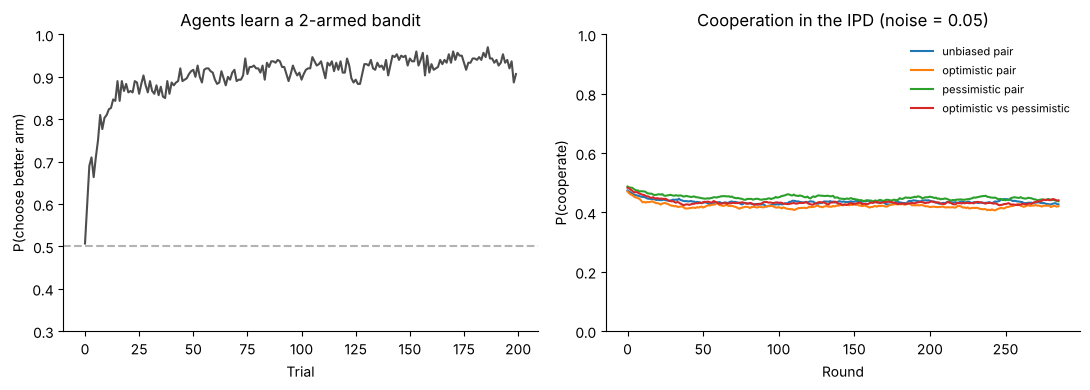

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(learn, color="0.3"); axes[0].axhline(0.5, ls="--", c="0.7")
axes[0].set(title="Agents learn a 2-armed bandit", xlabel="Trial",
            ylabel="P(choose better arm)", ylim=(0.3, 1))
smooth = lambda x, k=15: np.convolve(x, np.ones(k) / k, mode="valid")
for (p1, p2), runs in coop.items():
    axes[1].plot(smooth(runs.mean(axis=(0, 2))), label=f"{p1} vs {p2}" if p1 != p2 else f"{p1} pair")
axes[1].set(title=f"Cooperation in the IPD (noise = {NOISE})", xlabel="Round",
            ylabel="P(cooperate)", ylim=(0, 1))
axes[1].legend(frameon=False, fontsize=8)
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig("figures/01_sanity_checks.png", dpi=150); plt.show()